Импорт всех библиотек

In [1]:
import pandas as pd
from sklearn.utils import resample
from rdkit import Chem
from rdkit.Chem import AllChem, Descriptors
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.sequence import pad_sequences
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score
from lightgbm import early_stopping, log_evaluation
from sklearn.linear_model import Lasso, LassoCV
from sklearn.preprocessing import StandardScaler
import lightgbm as lgb
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Embedding, Bidirectional, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import random
import numpy as np
import tensorflow as tf


возобновляемость результатов

In [2]:
def set_seeds(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seeds(42)

Загрузка данных и первичный просмотр

In [3]:
url = "../data/delaney-processed.csv"
df = pd.read_csv(url)
print(df.head())
print(f"Столбцы в датасете: {df.columns.tolist()}")

  Compound ID  ESOL predicted log solubility in mols per litre  \
0   Amigdalin                                           -0.974   
1    Fenfuram                                           -2.885   
2      citral                                           -2.579   
3      Picene                                           -6.618   
4   Thiophene                                           -2.232   

   Minimum Degree  Molecular Weight  Number of H-Bond Donors  Number of Rings  \
0               1           457.432                        7                3   
1               1           201.225                        1                2   
2               1           152.237                        0                0   
3               2           278.354                        0                5   
4               2            84.143                        0                1   

   Number of Rotatable Bonds  Polar Surface Area  \
0                          7              202.32   
1           

 EDA – гистограмма целевой переменной

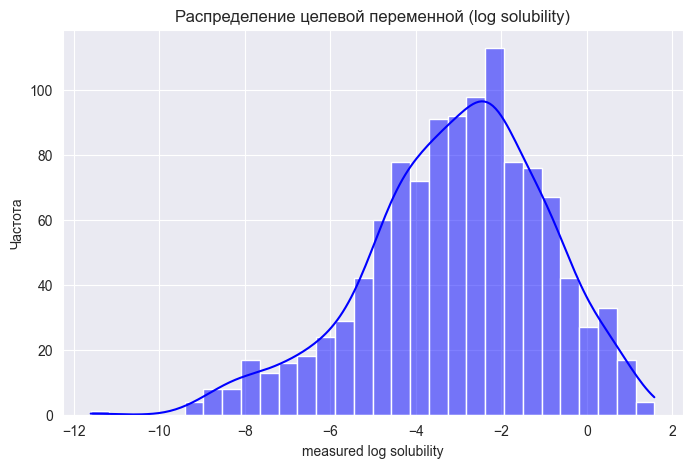

In [4]:
plt.figure(figsize=(8, 5))
sns.histplot(df['measured log solubility in mols per litre'], bins=30, kde=True, color='blue')
plt.title('Распределение целевой переменной (log solubility)')
plt.xlabel('measured log solubility')
plt.ylabel('Частота')
plt.show()

EDA – ящики с усами для ключевых дескрипторов

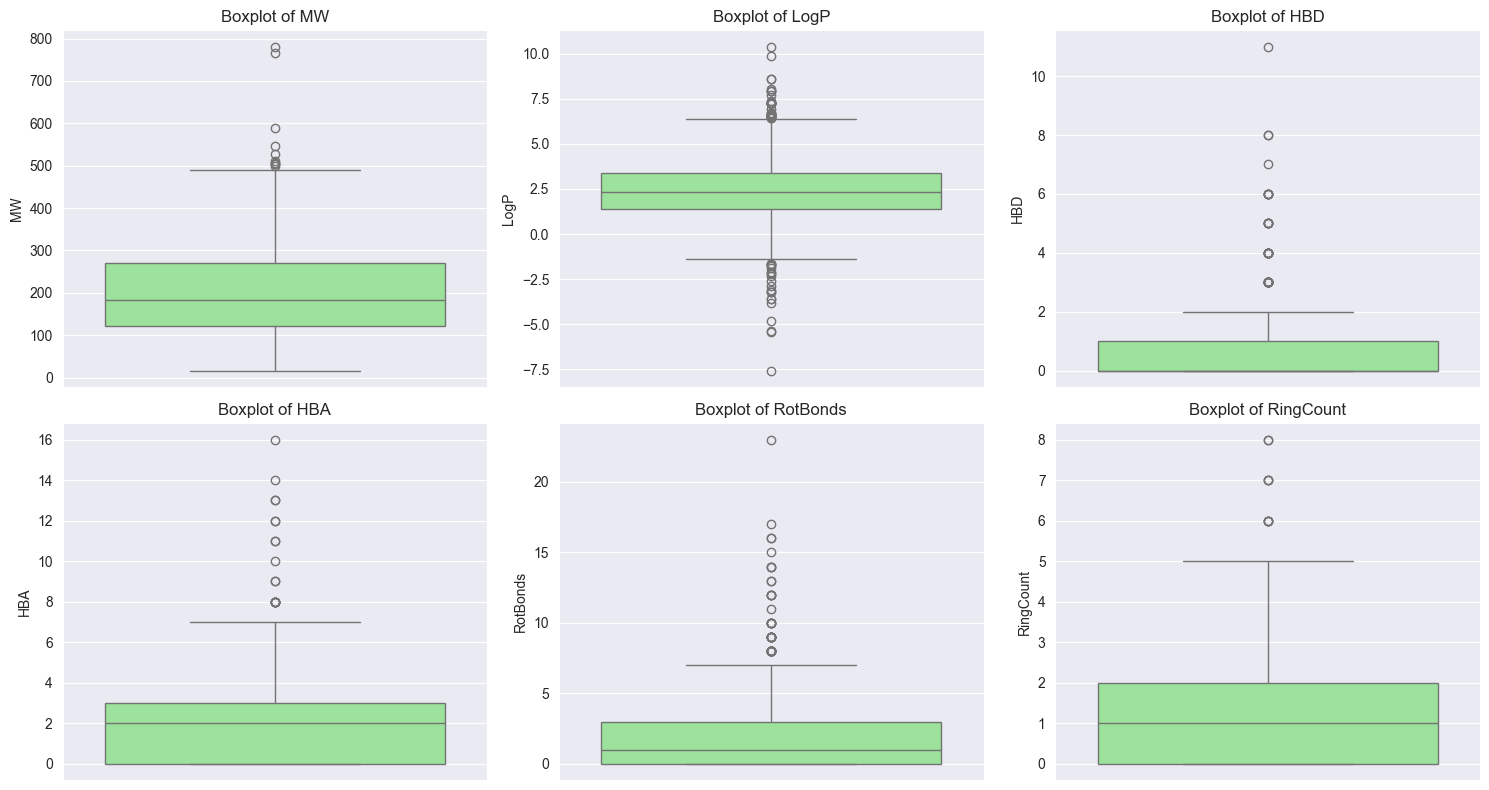

In [5]:
descr_list = []
for sm in df['smiles']:
    mol = Chem.MolFromSmiles(sm)
    if mol is not None:
        descr_list.append({
            'MW': Descriptors.MolWt(mol),
            'LogP': Descriptors.MolLogP(mol),
            'HBD': Descriptors.NumHDonors(mol),
            'HBA': Descriptors.NumHAcceptors(mol),
            'RotBonds': Descriptors.NumRotatableBonds(mol),
            'RingCount': Descriptors.RingCount(mol)
        })
    else:
        descr_list.append({k: np.nan for k in ['MW','LogP','HBD','HBA','RotBonds','RingCount']})
desc_df = pd.DataFrame(descr_list)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, desc_df.columns):
    sns.boxplot(y=desc_df[col], ax=ax, color='lightgreen')
    ax.set_title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

EDA – матрица корреляций (Spearman)

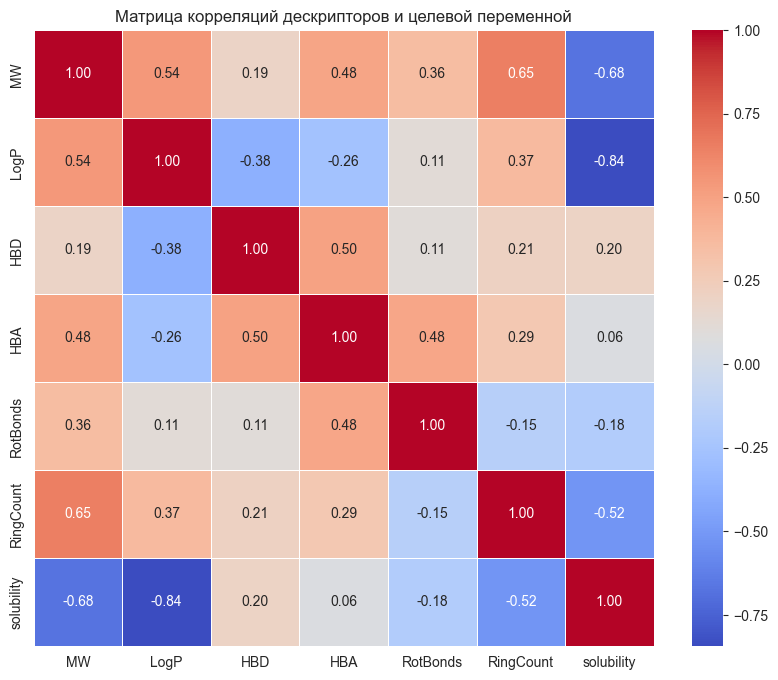

In [6]:
desc_df['solubility'] = df['measured log solubility in mols per litre'].values
corr_matrix = desc_df.corr(method='spearman')

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Матрица корреляций дескрипторов и целевой переменной')
plt.show()

Преобразование SMILES в признаки (fingerprints + дескрипторы) и последовательности для LSTM

In [7]:
def compute_features(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return np.zeros(1024 + 4)
    fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=1024)
    fp_arr = np.array(fp)
    mw = Descriptors.MolWt(mol)
    logp = Descriptors.MolLogP(mol)
    hbd = Descriptors.NumHDonors(mol)
    hba = Descriptors.NumHAcceptors(mol)
    desc_arr = np.array([mw, logp, hbd, hba])
    return np.concatenate([fp_arr, desc_arr])

X_features = np.array([compute_features(sm) for sm in df['smiles']])
y = df['measured log solubility in mols per litre'].values

all_chars = sorted(set(''.join(df['smiles'])))
char_to_idx = {ch: i+1 for i, ch in enumerate(all_chars)}
max_len = max(len(s) for s in df['smiles'])

def smiles_to_seq(smiles):
    return [char_to_idx.get(ch, 0) for ch in smiles]

X_seq_list = [smiles_to_seq(s) for s in df['smiles']]
X_seq_pad = pad_sequences(X_seq_list, maxlen=max_len, padding='post', truncating='post')

[17:03:22] DEPRECATION WARNING: please use MorganGenerator
[17:03:22] DEPRECATION WARNING: please use MorganGenerator
[17:03:22] DEPRECATION WARNING: please use MorganGenerator
[17:03:22] DEPRECATION WARNING: please use MorganGenerator
[17:03:22] DEPRECATION WARNING: please use MorganGenerator
[17:03:22] DEPRECATION WARNING: please use MorganGenerator
[17:03:22] DEPRECATION WARNING: please use MorganGenerator
[17:03:22] DEPRECATION WARNING: please use MorganGenerator
[17:03:22] DEPRECATION WARNING: please use MorganGenerator
[17:03:22] DEPRECATION WARNING: please use MorganGenerator
[17:03:22] DEPRECATION WARNING: please use MorganGenerator
[17:03:22] DEPRECATION WARNING: please use MorganGenerator
[17:03:22] DEPRECATION WARNING: please use MorganGenerator
[17:03:22] DEPRECATION WARNING: please use MorganGenerator
[17:03:22] DEPRECATION WARNING: please use MorganGenerator
[17:03:22] DEPRECATION WARNING: please use MorganGenerator
[17:03:22] DEPRECATION WARNING: please use MorganGenerat

Разделение на train и test (одинаковое для всех моделей)

In [8]:
X_train_feat, X_test_feat, X_train_seq, X_test_seq, y_train, y_test = train_test_split(
    X_features, X_seq_pad, y, test_size=0.2, random_state=42
)

Lasso-регрессия (регуляризация L1, автоматический отбор признаков)

In [9]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled = scaler.transform(X_test_feat)

lasso_cv = LassoCV(alphas=np.logspace(-4, 1, 50), cv=5, random_state=42, max_iter=10000)
lasso_cv.fit(X_train_scaled, y_train)
best_alpha = lasso_cv.alpha_
print(f"Best alpha from CV: {best_alpha:.5f}")

lasso = Lasso(alpha=best_alpha, random_state=42, max_iter=10000)
lasso.fit(X_train_scaled, y_train)

y_pred_lasso = lasso.predict(X_test_scaled)
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
r2_lasso = r2_score(y_test, y_pred_lasso)
print(f"Lasso Test RMSE: {rmse_lasso:.4f}, R²: {r2_lasso:.4f}")

n_selected = np.sum(lasso.coef_ != 0)
print(f"Ненулевых коэффициентов: {n_selected} из {X_train_feat.shape[1]}")

Best alpha from CV: 0.02812
Lasso Test RMSE: 0.9339, R²: 0.8155
Ненулевых коэффициентов: 200 из 1028


LightGBM с кросс-валидацией и early stopping

In [10]:
params = {
    'objective': 'regression',
    'metric': 'rmse',
    'boosting': 'gbdt',
    'num_leaves': 31,
    'learning_rate': 0.05,
    'feature_fraction': 0.9,
    'bagging_fraction': 0.8,
    'bagging_freq': 5,
    'verbose': -1,
    'random_state': 42
}

train_data = lgb.Dataset(X_train_feat, label=y_train)

callbacks = [
    early_stopping(stopping_rounds=20, verbose=True),
    log_evaluation(period=50)
]

cv_results = lgb.cv(
    params, train_data, num_boost_round=500, nfold=5,
    stratified=False, shuffle=True, callbacks=callbacks
)

best_round = len(cv_results['valid rmse-mean'])
print(f"LightGBM CV best iteration: {best_round}")
print(f"LightGBM CV RMSE: {cv_results['valid rmse-mean'][-1]:.4f} (+/- {cv_results['valid rmse-stdv'][-1]:.4f})")

lgb_model = lgb.LGBMRegressor(**params, n_estimators=best_round)
lgb_model.fit(X_train_feat, y_train)
y_pred_lgb = lgb_model.predict(X_test_feat)
rmse_lgb = np.sqrt(mean_squared_error(y_test, y_pred_lgb))
r2_lgb = r2_score(y_test, y_pred_lgb)
print(f"LightGBM Test RMSE: {rmse_lgb:.4f}, R²: {r2_lgb:.4f}")

Training until validation scores don't improve for 20 rounds
[50]	valid's rmse: 0.730309 + 0.0429336
[100]	valid's rmse: 0.659845 + 0.0379447
[150]	valid's rmse: 0.640558 + 0.033497
[200]	valid's rmse: 0.628873 + 0.0326028
[250]	valid's rmse: 0.622937 + 0.0283126
Early stopping, best iteration is:
[276]	valid's rmse: 0.618359 + 0.0281777
LightGBM CV best iteration: 276
LightGBM CV RMSE: 0.6184 (+/- 0.0282)
LightGBM Test RMSE: 0.6987, R²: 0.8967


C:\Users\user\PycharmProjects\PythonProject\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


LSTM с кросс-валидацией (5-fold) и финальным обучением

In [11]:
vocab_size = len(char_to_idx) + 1
embedding_dim = 64
lstm_units = 64
epochs = 50
batch_size = 32

kfold = KFold(n_splits=5, shuffle=True, random_state=42)
cv_rmse_lstm = []

for fold, (train_idx, val_idx) in enumerate(kfold.split(X_train_seq)):
    print(f"LSTM Fold {fold+1}/{kfold.n_splits}")
    X_tr_seq = X_train_seq[train_idx]
    X_val_seq = X_train_seq[val_idx]
    y_tr = y_train[train_idx]
    y_val = y_train[val_idx]

    model = Sequential([
        Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_len),
        Bidirectional(LSTM(units=lstm_units, dropout=0.2, recurrent_dropout=0.2)),
        Dense(32, activation='relu'),
        Dropout(0.3),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

    model.fit(X_tr_seq, y_tr,
              validation_data=(X_val_seq, y_val),
              epochs=epochs, batch_size=batch_size,
              callbacks=[early_stop], verbose=0)

    y_pred_val = model.predict(X_val_seq, verbose=0).flatten()
    rmse = np.sqrt(mean_squared_error(y_val, y_pred_val))
    cv_rmse_lstm.append(rmse)
    print(f"  RMSE: {rmse:.4f}")

print(f"LSTM CV RMSE (5-fold): {np.mean(cv_rmse_lstm):.4f} (+/- {np.std(cv_rmse_lstm):.4f})")


final_lstm = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_len),
    Bidirectional(LSTM(units=lstm_units, dropout=0.2, recurrent_dropout=0.2)),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1)
])
final_lstm.compile(optimizer='adam', loss='mse', metrics=['mae'])
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

split = int(0.8 * len(X_train_seq))
X_tr_final = X_train_seq[:split]
X_val_final = X_train_seq[split:]
y_tr_final = y_train[:split]
y_val_final = y_train[split:]

final_lstm.fit(X_tr_final, y_tr_final,
               validation_data=(X_val_final, y_val_final),
               epochs=epochs, batch_size=batch_size,
               callbacks=[early_stop], verbose=1)

y_pred_lstm = final_lstm.predict(X_test_seq, verbose=0).flatten()
rmse_lstm = np.sqrt(mean_squared_error(y_test, y_pred_lstm))
r2_lstm = r2_score(y_test, y_pred_lstm)
print(f"LSTM Test RMSE: {rmse_lstm:.4f}, R²: {r2_lstm:.4f}")

C:\Users\user\PycharmProjects\PythonProject\.venv\Lib\site-packages\keras\src\layers\core\embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


LSTM Fold 1/5
  RMSE: 0.6881
LSTM Fold 2/5


C:\Users\user\PycharmProjects\PythonProject\.venv\Lib\site-packages\keras\src\layers\core\embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


  RMSE: 0.9316
LSTM Fold 3/5


C:\Users\user\PycharmProjects\PythonProject\.venv\Lib\site-packages\keras\src\layers\core\embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


...

  RMSE: 0.8309
LSTM Fold 5/5


C:\Users\user\PycharmProjects\PythonProject\.venv\Lib\site-packages\keras\src\layers\core\embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


  RMSE: 0.8265
LSTM CV RMSE (5-fold): 0.8120 (+/- 0.0788)
Epoch 1/50


C:\Users\user\PycharmProjects\PythonProject\.venv\Lib\site-packages\keras\src\layers\core\embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


23/23 ━━━━━━━━━━━━━━━━━━━━ 7s 121ms/step - loss: 8.4502 - mae: 2.3091 - val_loss: 3.9110 - val_mae: 1.5477
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 95ms/step - loss: 3.8200 - mae: 1.5143 - val_loss: 2.5831 - val_mae: 1.2186
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 104ms/step - loss: 2.7687 - mae: 1.2976 - val_loss: 2.0146 - val_mae: 1.1128
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 104ms/step - loss: 2.4065 - mae: 1.1989 - val_loss: 1.6029 - val_mae: 1.0028
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 104ms/step - loss: 2.1245 - mae: 1.1372 - val_loss: 1.6086 - val_mae: 1.0118
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 106ms/step - loss: 1.8973 - mae: 1.0861 - val_loss: 1.4229 - val_mae: 0.9476
Epoch 7/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 104ms/step - loss: 1.7774 - mae: 1.0637 - val_loss: 1.4715 - val_mae: 0.9739
Epoch 8/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 116ms/step - loss: 1.7410 - mae: 1.0521 - val_loss: 1.3672 - val_mae: 0.9337
Epoch 9/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 117ms/step - loss: 1.8254 -

Ансамбль (усреднение LightGBM и LSTM) и сводная таблица

In [12]:
rmse_lgb_cv = cv_results['valid rmse-mean'][-1]
rmse_lstm_cv = np.mean(cv_rmse_lstm)

print(f"LightGBM CV RMSE (train): {rmse_lgb_cv:.4f}")
print(f"LSTM CV RMSE (train):     {rmse_lstm_cv:.4f}")

w1 = 1 / rmse_lgb_cv
w2 = 1 / rmse_lstm_cv
y_pred_ensemble = (w1 * y_pred_lgb + w2 * y_pred_lstm) / (w1 + w2)
rmse_ens = np.sqrt(mean_squared_error(y_test, y_pred_ensemble))
r2_ens = r2_score(y_test, y_pred_ensemble)
print(f"Ensemble (LightGBM+LSTM) Test RMSE: {rmse_ens:.4f}, R²: {r2_ens:.4f}")

print("="*50)
print("Сводная таблица результатов на тестовой выборке")
print("="*50)
print(f"Lasso (L1 регуляризация):       RMSE = {rmse_lasso:.4f}, R² = {r2_lasso:.4f}")
print(f"LightGBM:                       RMSE = {rmse_lgb:.4f}, R² = {r2_lgb:.4f}")
print(f"LSTM:                           RMSE = {rmse_lstm:.4f}, R² = {r2_lstm:.4f}")
print(f"Ensemble (LightGBM+LSTM):       RMSE = {rmse_ens:.4f}, R² = {r2_ens:.4f}")

LightGBM CV RMSE (train): 0.6184
LSTM CV RMSE (train):     0.8120
Ensemble (LightGBM+LSTM) Test RMSE: 0.6750, R²: 0.9036
Сводная таблица результатов на тестовой выборке
Lasso (L1 регуляризация):       RMSE = 0.9339, R² = 0.8155
LightGBM:                       RMSE = 0.6987, R² = 0.8967
LSTM:                           RMSE = 0.7697, R² = 0.8747
Ensemble (LightGBM+LSTM):       RMSE = 0.6750, R² = 0.9036


Визуализация предсказаний для всех моделей

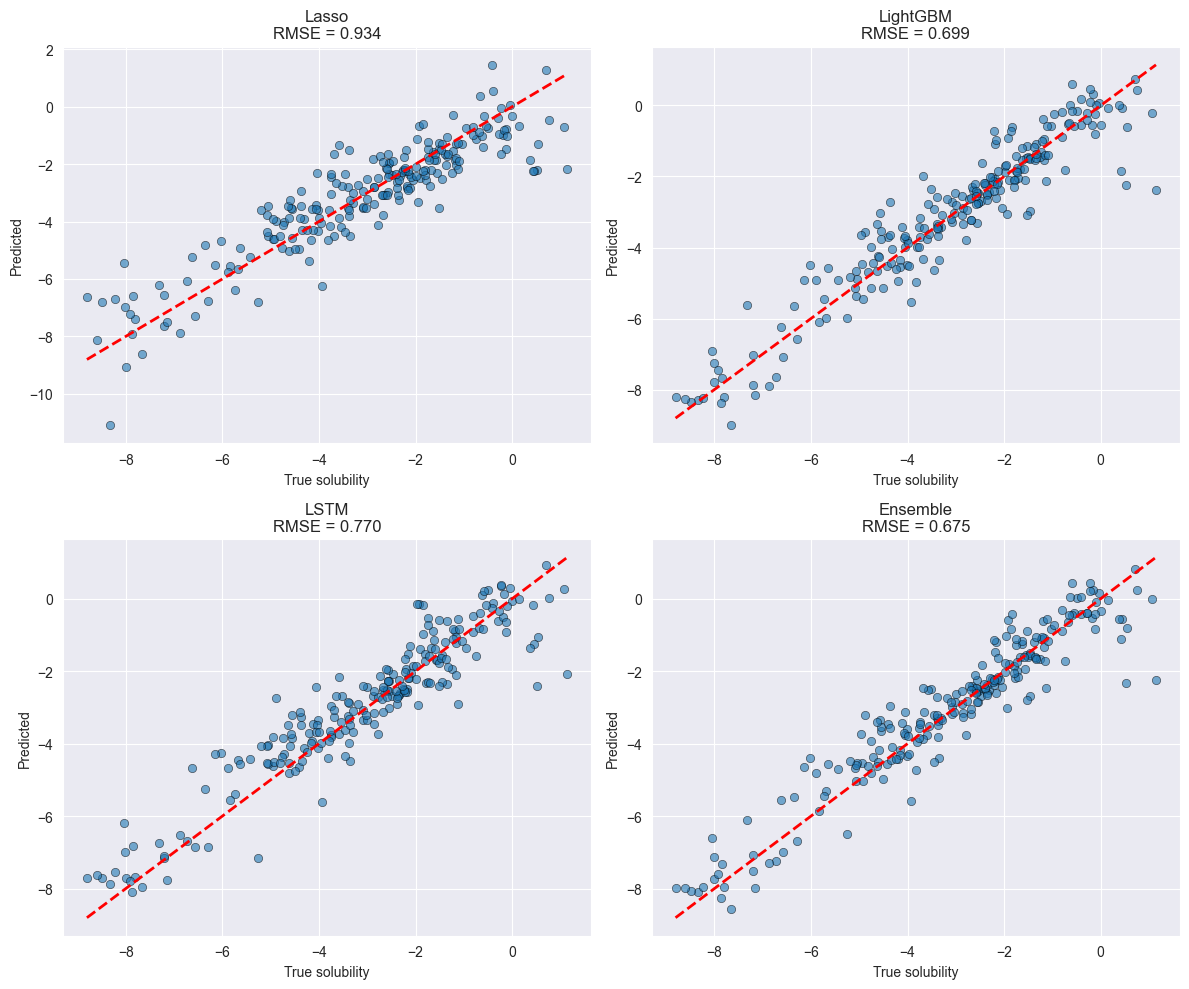

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()
models = [
    ('Lasso', y_pred_lasso),
    ('LightGBM', y_pred_lgb),
    ('LSTM', y_pred_lstm),
    ('Ensemble', y_pred_ensemble)
]
for ax, (name, pred) in zip(axes, models):
    ax.scatter(y_test, pred, alpha=0.6, edgecolors='k', lw=0.5)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    ax.set_xlabel('True solubility')
    ax.set_ylabel('Predicted')
    ax.set_title(f'{name}\nRMSE = {np.sqrt(mean_squared_error(y_test, pred)):.3f}')
plt.tight_layout()
plt.show()

Проверка статистической разности между lightGBM и ансамблем

In [14]:



n_iterations = 1000
diff_rmse = []

for _ in range(n_iterations):
    # Бутстрап-выборка индексов теста (того же размера)
    indices = resample(range(len(y_test)), replace=True, n_samples=len(y_test))
    y_true_bs = y_test[indices]
    y_pred_lgb_bs = y_pred_lgb[indices]
    y_pred_ens_bs = y_pred_ensemble[indices]

    rmse_lgb = np.sqrt(mean_squared_error(y_true_bs, y_pred_lgb_bs))
    rmse_ens = np.sqrt(mean_squared_error(y_true_bs, y_pred_ens_bs))
    diff_rmse.append(rmse_lgb - rmse_ens)  # положительное = ансамбль лучше

# p-value для гипотезы: разница <= 0
p_value = (np.array(diff_rmse) <= 0).mean()
print(f"Вероятность того, что LightGBM не хуже ансамбля: {p_value:.4f}")
if p_value < 0.05:
    print("Ансамбль статистически значимо лучше LightGBM (p < 0.05).")
else:
    print("Разница статистически не значима (возможно, нужен больший датасет).")

Вероятность того, что LightGBM не хуже ансамбля: 0.0870
Разница статистически не значима (возможно, нужен больший датасет).
